In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show a 3D volume

A volume is a 3D array with one value per atlas voxel. This page builds one, plots it on coronal, sagittal and horizontal slices, on a tilted slice and on the dorsal cortex flat map, and shows how its shape follows the atlas resolution, including on a dataset's own 200 µm grid. The same calls work for any volume you have, such as an image stack registered to the atlas, or one value per voxel from your own analysis.

## A volume matches the atlas image

The volume must have the same shape as the atlas image, indexed (AP, ML, DV). Voxels set to `NaN`, such as those outside the brain, are left unpainted so the background shows through.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from iblatlas.atlas import AllenAtlas

ba = AllenAtlas(res_um=50)
ba.image.shape

(264, 228, 160)

As an example, this volume is a smooth blob centred in the left thalamus, built from the voxel coordinates of the atlas (in metres from bregma).

In [3]:
ap, ml, dv = np.meshgrid(ba.bc.yscale, ba.bc.xscale, ba.bc.zscale, indexing='ij')
distance_sq = (ap - (-0.0015)) ** 2 + (ml - (-0.002)) ** 2 + (dv - (-0.003)) ** 2
volume = np.exp(-distance_sq / (2 * 0.001 ** 2)).astype(np.float32)

# leave voxels outside the brain, and voxels with almost no signal, unpainted
volume[(ba.label == 0) | (volume < 0.02)] = np.nan

assert volume.shape == ba.image.shape

## Plot a slice

`plot_volume_on_slice` takes the volume, the slice orientation (`'coronal'`, `'sagittal'` or `'horizontal'`) and the position of the slice in micrometres.

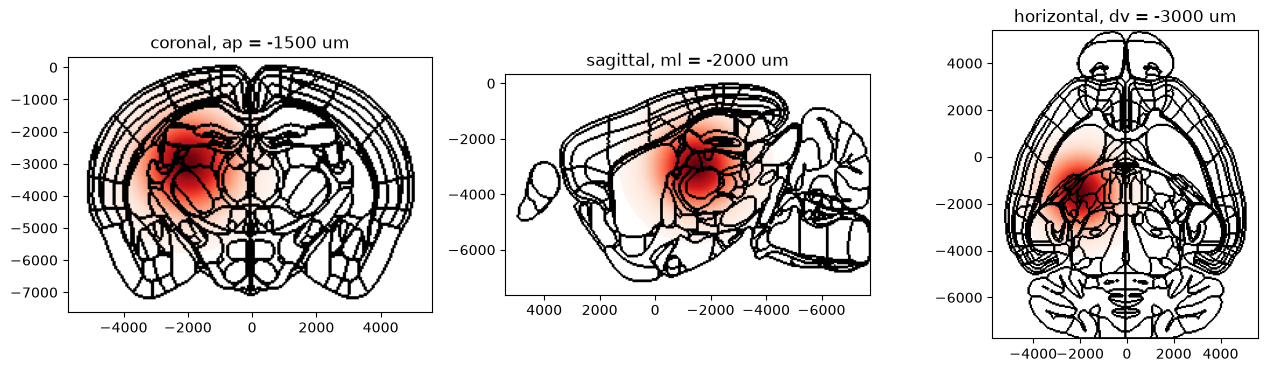

In [4]:
from iblatlas.plots import plot_volume_on_slice

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
plot_volume_on_slice(volume, coord=-1500, slice='coronal', brain_atlas=ba, ax=axs[0])
plot_volume_on_slice(volume, coord=-2000, slice='sagittal', brain_atlas=ba, ax=axs[1])
plot_volume_on_slice(volume, coord=-3000, slice='horizontal', brain_atlas=ba, ax=axs[2])
axs[0].set_title('coronal, ap = -1500 um')
axs[1].set_title('sagittal, ml = -2000 um')
axs[2].set_title('horizontal, dv = -3000 um');

## Colours, background and region boundaries

- `cmap` and `clevels` set the colormap and its limits, and `show_cbar=True` adds a colour bar. With a colour bar the function also returns the colorbar.
- `background` is `'boundary'` (region outlines, the default) or `'image'` (the atlas template image).
- `mapping` sets the regions that the boundaries outline: `'Allen'`, `'Beryl'` or `'Cosmos'`. See [Brain region mappings](../explanation/brain-region-mappings.qmd).

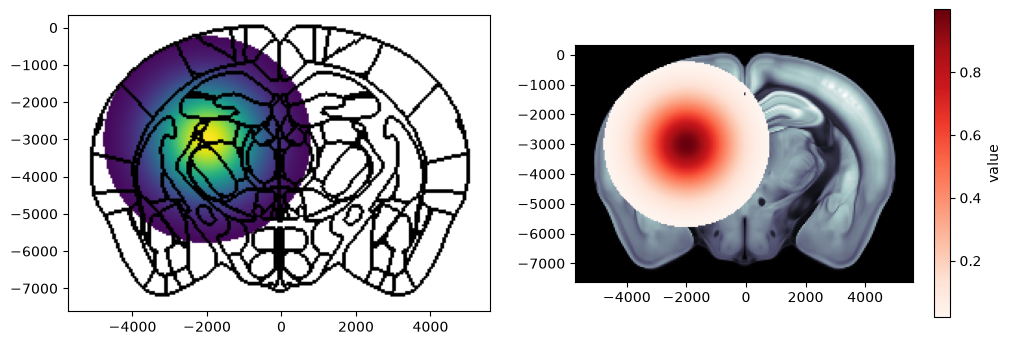

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_volume_on_slice(volume, coord=-1500, slice='coronal', mapping='Beryl', background='boundary',
                     cmap='viridis', clevels=[0, 1], brain_atlas=ba, ax=axs[0])
fig, ax, cbar = plot_volume_on_slice(volume, coord=-1500, slice='coronal', background='image',
                                     cmap='Reds', show_cbar=True, brain_atlas=ba, ax=axs[1])
cbar.set_label('value')

## On a tilted slice

`tilted_slice` cuts the plane that contains a line, such as a probe track, and returns it with its extent in metres. With `axis=1` the plane follows the line's tilt in AP. Pass the volume as `volume`:

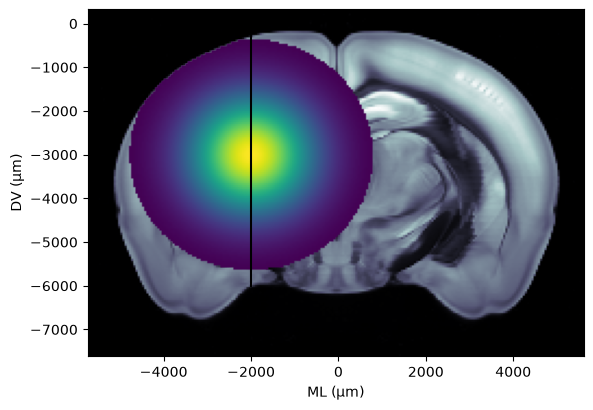

In [6]:
# A line from the brain surface down through the blob, tilted in AP; ML, AP, DV in metres
line = np.array([[-0.002, -0.0005, 0], [-0.002, -0.0025, -0.006]])
tslice, width, height, _ = ba.tilted_slice(line, axis=1, volume=volume)
template, *_ = ba.tilted_slice(line, axis=1, volume='image')

fig, ax = plt.subplots()
ax.imshow(template, extent=np.r_[width, height] * 1e6, cmap='bone')
ax.imshow(tslice, extent=np.r_[width, height] * 1e6)
ax.plot(line[:, 0] * 1e6, line[:, 2] * 1e6, color='k')
ax.set(xlabel='ML (µm)', ylabel='DV (µm)');

## On the dorsal cortex flat map

`project_volume_onto_flatmap` follows the Allen streamlines from each pixel of the dorsal cortex flat map down through the cortex and aggregates the volume's values along each, here by their maximum. Set `res_um` to the resolution the volume was built at. Only the cortex is projected, so the blob shows where it reaches the cortex above the thalamus. For the streamlines, see [Find how deep a point sits in cortex](find-cortical-depth-of-a-point.ipynb).

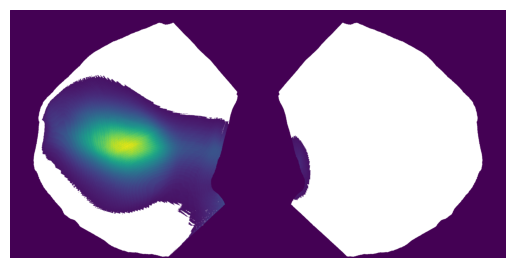

In [7]:
from iblatlas.streamlines.utils import project_volume_onto_flatmap

proj, fig, ax = project_volume_onto_flatmap(volume, res_um=50, aggr='max', plot=True)
ax.set_axis_off()

## Resolution

The atlas is available at 10, 25 and 50 um. A volume has to be built for the resolution of the atlas it is plotted on: the same blob has a different shape at each, and a mismatch raises an assertion error.

In [8]:
for res_um in (25, 50):
    print(res_um, AllenAtlas(res_um=res_um).image.shape)

25 (528, 456, 320)
50 (264, 228, 160)


Pass the atlas you built the volume for as `brain_atlas`. If you leave it out, the function loads the default 25 um atlas, so a volume made at another resolution will not match.

## A dataset's own 200 µm atlas

The gene expression, lipid and MERFISH volumes sit on a 200 µm grid of their own, with the axes stored in a different order (ML, DV, AP). `agea.load_atlas()` builds the matching atlas, a download of a few MB, without the volumes themselves. Build or load the volume on that grid and pass the atlas as `brain_atlas`. Here the blob is rebuilt on it:

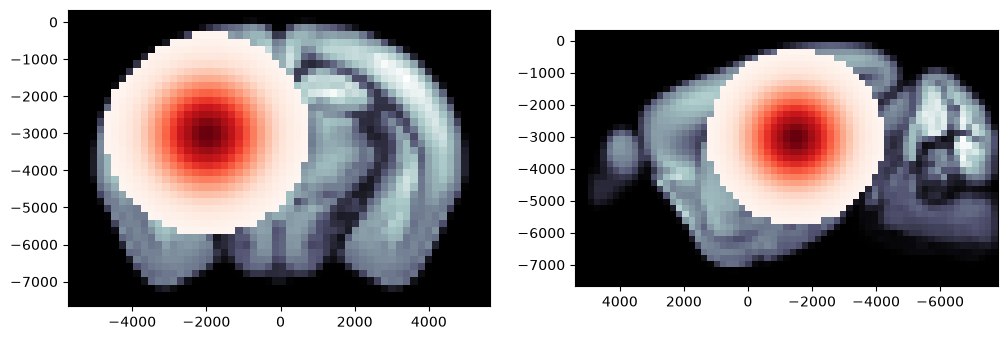

In [9]:
from iblatlas.genomics import agea

atlas_200 = agea.load_atlas()
ml, ap, dv = np.meshgrid(atlas_200.bc.xscale, atlas_200.bc.yscale, atlas_200.bc.zscale, indexing='ij')
distance_sq = (ap - (-0.0015)) ** 2 + (ml - (-0.002)) ** 2 + (dv - (-0.003)) ** 2
# reorder the axes from ML, AP, DV to the order this atlas stores them in
volume_200 = np.transpose(np.exp(-distance_sq / (2 * 0.001 ** 2)), atlas_200.xyz2dims)
volume_200[(atlas_200.label == 0) | (volume_200 < 0.02)] = np.nan

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
plot_volume_on_slice(volume_200, coord=-1500, slice='coronal', background='image',
                     brain_atlas=atlas_200, ax=axs[0])
plot_volume_on_slice(volume_200, coord=-2000, slice='sagittal', background='image',
                     brain_atlas=atlas_200, ax=axs[1]);

## Where a volume comes from

- **From points.** `compute_volume_from_points` places points in their voxels, aggregates the points that share a voxel (sum, count, mean and others) and can smooth the result. See [Show values per point or cell](plot-points-on-slices.ipynb).
- **From a loaded dataset.** The gene expression, lipid and MERFISH how-tos load volumes that are already in the atlas space: [gene expression](load-gene-expression-agea.ipynb), [lipids](load-lipids.ipynb) and [MERFISH](load-merfish.ipynb).